# Lab 9&10: PCA Analysis
## With Hypoxia Data

------
Name = "Noah Runions"

Before you turn this assignment in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel Restart) and then **run all cells** (in the menubar, select Cell and Run All).

Add as many comments as you could when you solve the problem, which can help your remember what you have done.


***Submission***: For Python people, submit this Jupyter Notebook only




***Figures:*** For any figures, label axis and title clearly for full points. 



Lab TA: Lee Ochs

## Lab Objectives:

1. Data visualization 
2. Prepare data for PCA 
3. Interpret PCA results
4. Perform some ANOVA analysis for the PCA results

## Lab Activities: 
This lab has two parts, A (30 points), B (30 points),and bonus questions (5 points). Be sure to follow the instructions and complete each parts. 


Part A (30 points): Data visulization and preparation

In [1]:
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA

### Part A (30 points): Data Exploration, Visualization, and create PCA model

In [3]:
#read your data in
lab10_observation = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab10\Lab10_observations_gulf_final.csv')

- plot pairwise relationships to see if you can spot any patterns 
- plot varaibles oxy, sal, nit, sil, seat, pho, sdep, and bdep
- color them based on one or two variables you think may be important

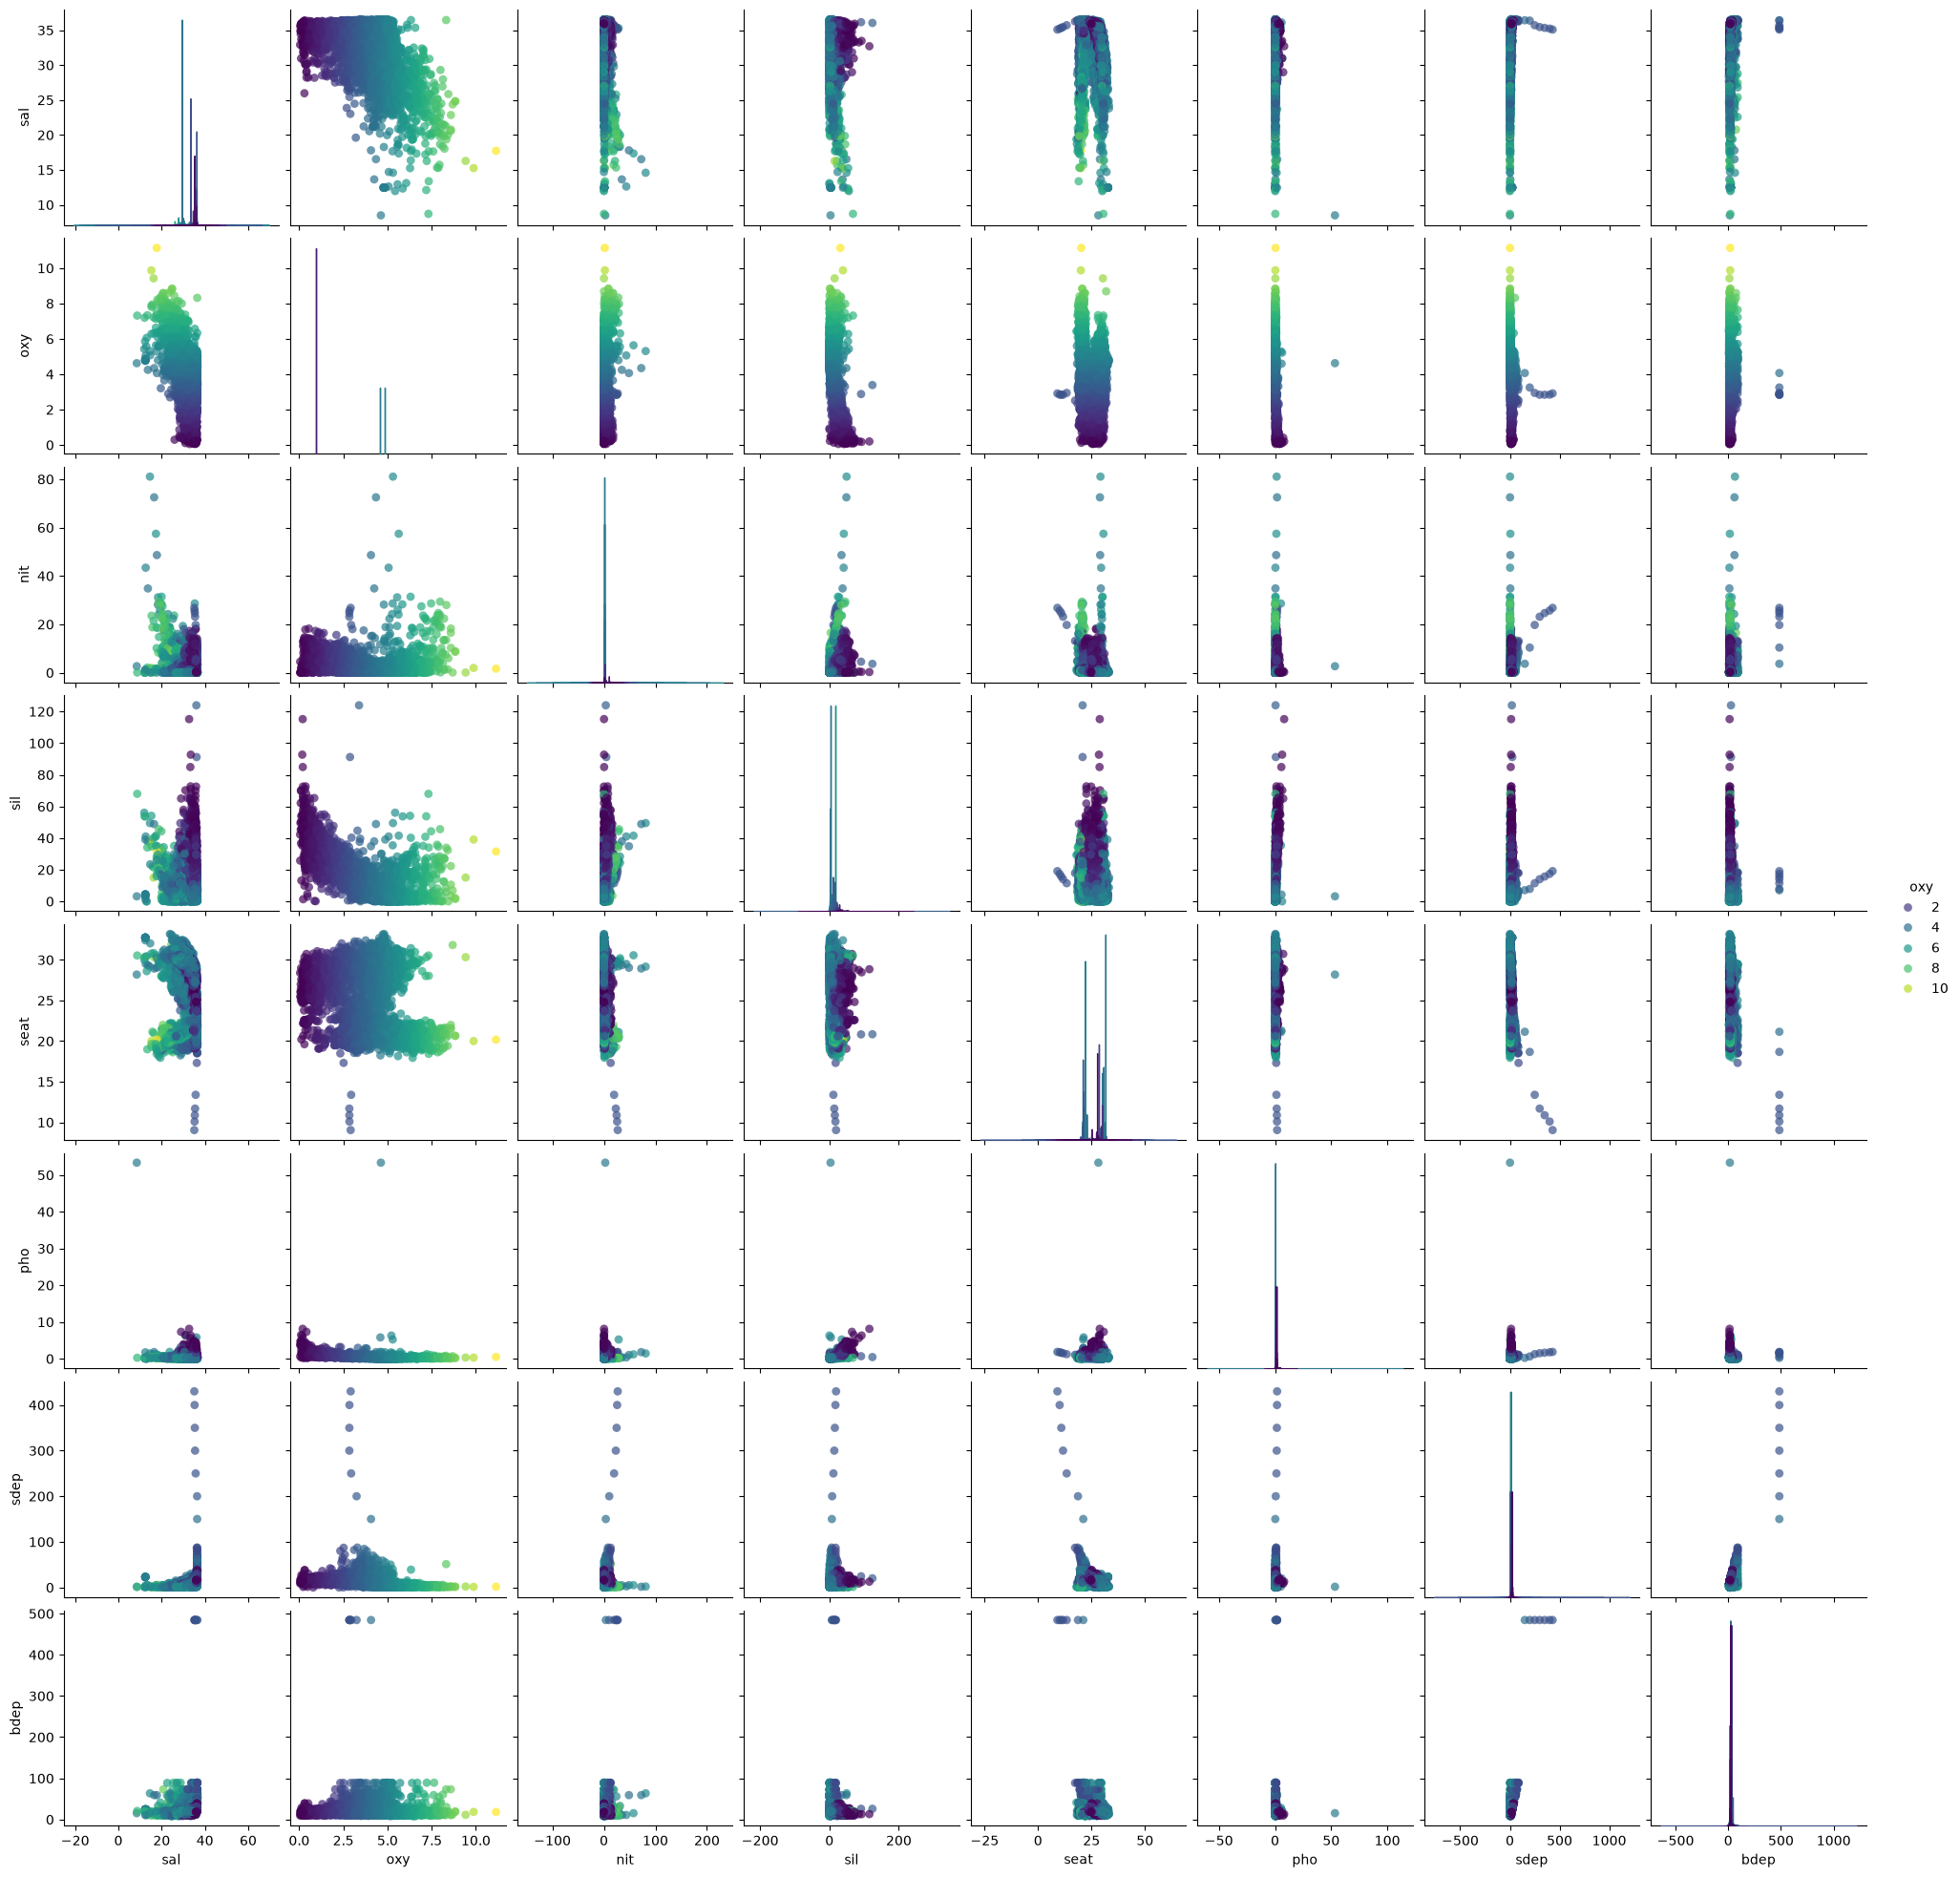

In [4]:
pca_data = lab10_observation[['sal','oxy','nit','sil','seat','pho', 'sdep', 'bdep']]

sns.pairplot(
    pca_data,
    vars=['sal','oxy','nit','sil','seat','pho', 'sdep', 'bdep'],
    hue='oxy',
    palette='viridis',
    diag_kind='kde',
    plot_kws={'alpha': 0.7, 's': 40, 'edgecolor': 'none'},
    diag_kws={'color': 'black'}
)

plt.show()

- Describe the trend between oxygen, salinity, temperature, and nutrients (silicate and nitrate).
- What do you think of the potential cause of low oxygen indicated by the data?
- Answer:

In [13]:
#prepare your data for PCA
#select the variables you want to include in the PCA analysis
#what would you do for NA values?
pca_data= pca_data.dropna()

Bonus Point (5 point)
Plot the distribution of all the variables of your choice, use sns's kde.

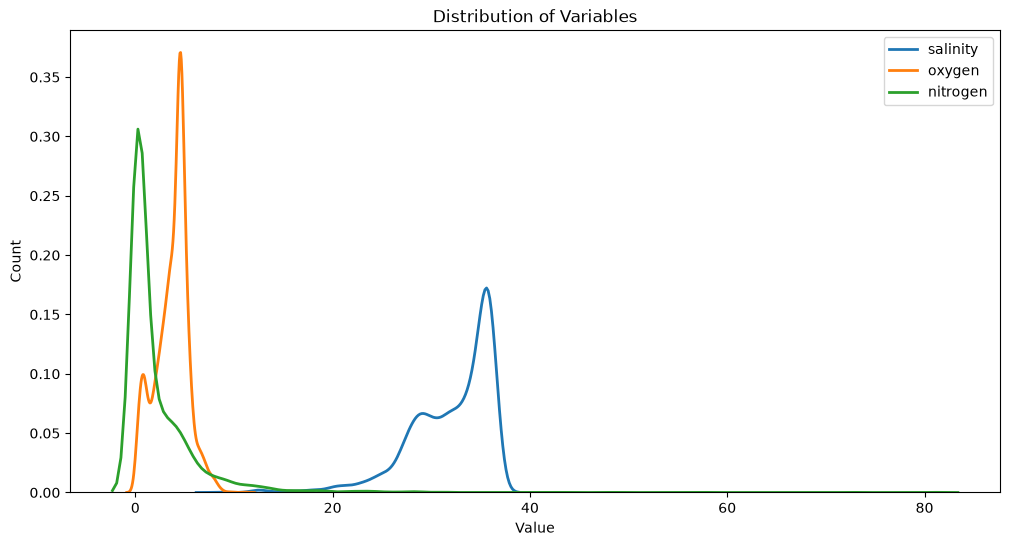

In [14]:
#bonus point code here
plt.figure(figsize=(12,6))
sns.kdeplot(pca_data['sal'], label="salinity", linewidth=2)
sns.kdeplot(pca_data['oxy'], label="oxygen", linewidth=2)
sns.kdeplot(pca_data['nit'], label="nitrogen", linewidth=2)
plt.title("Distribution of Variables")
plt.xlabel("Value")
plt.ylabel("Count")
plt.legend()
plt.show()

Why did you chose these variables? (explain them with the pairwise data and the trend)
- Answer:

In [15]:
#normalize the data for PCA analysis
scaler = StandardScaler()
pca_data_scaled = scaler.fit_transform(pca_data)
features = ['sal','oxy','nit','sil','seat','pho', 'sdep', 'bdep']
scaled_df = pd.DataFrame(pca_data_scaled, columns=features)
scaled_df.head()


,sal,oxy,nit,sil,seat,pho,sdep,bdep
0,-2.868185,0.489540,0.447879,-0.314000,-1.138505,-0.024388,-0.517237,-0.595943
1,-0.609675,0.291566,0.118822,-0.490549,-1.153440,-0.024388,-0.471400,-0.595943
2,-0.474743,-2.082908,-0.106195,-0.070958,-1.169775,-0.177925,-0.170185,-0.595943
3,-0.947803,1.335043,-0.183621,-0.888741,-1.073483,-0.116510,-0.654747,-0.160001
4,-0.722771,1.261945,1.556028,-0.127515,-1.088222,0.825188,-0.648199,-0.160001


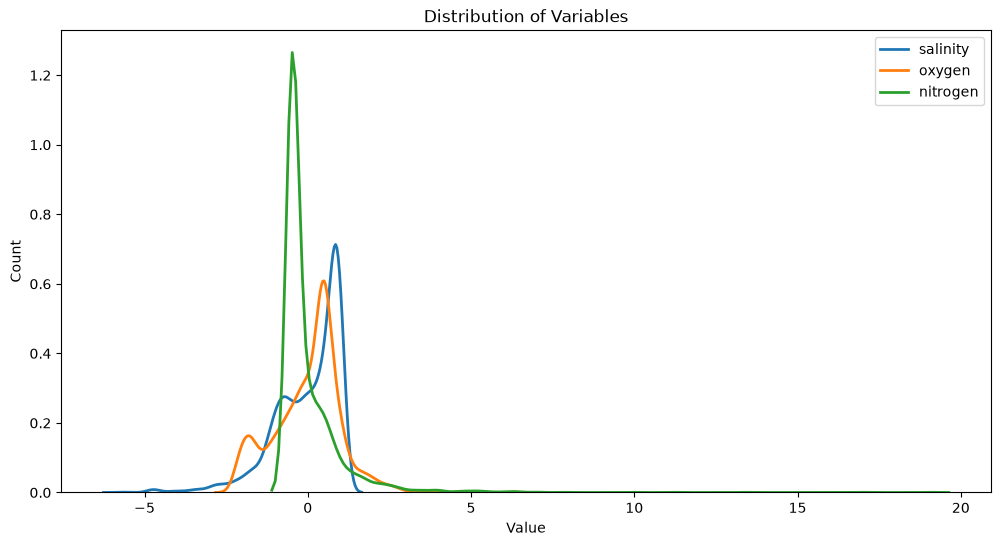

In [16]:
#plot distribution of your variables after normalization, use sns's kde
plt.figure(figsize=(12,6))
sns.kdeplot(scaled_df['sal'], label="salinity", linewidth=2)
sns.kdeplot(scaled_df['oxy'], label="oxygen", linewidth=2)
sns.kdeplot(scaled_df['nit'], label="nitrogen", linewidth=2)
plt.title("Distribution of Variables")
plt.xlabel("Value")
plt.ylabel("Count")
plt.legend()
plt.show()


Please answer the following questions:
- How many variable(s) show a "bimodal" distribution? And what are they?
- 
- How many variable(s) show a "positively skewed unimodal" distribution? And what are they?
- 
- How many variable(s) show a "negatively skewed unimodal" distribution? And what are they?
- 
- How many variable(s) show a "uniform" distribution? And what are they?
- 


- What is the difference between the distribution of variable before and after normalization?
- (shape, spread, values)
- answer:
- Why do we normalize/scale the data for PCA here? 

In [ ]:
#create PCA model and save the results
#include the new data in PCA space, explained variance, and loadings
#and save them to new data frames


#these few lines of code run the PCA and save the results
pca = PCA() # initilize a PCA model, now it is empty, we did not specify number of componets, so it will keep all components by default
data_pcaed = pca.fit_transform(pca_data_scaled)  #the new data but in the PCA space
coeff = pca.components_           # (loadings)
latent = pca.explained_variance_    #
explained_var_ratio = pca.explained_variance_ratio_  # variance %

array([0.31760657, 0.22772684, 0.15935426, 0.11774893, 0.09375213,
       0.04871189, 0.01987896, 0.01522042])

In [19]:
df_pca = pd.DataFrame(
    data_pcaed,
    columns=['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8']
)

df_pca.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
0,1.538667,0.057060,2.247329,-0.328224,0.440258,-1.080791,0.968147,-0.925517
1,0.711747,0.118639,0.666530,-1.023053,0.470911,-0.034654,0.435230,-0.442621
2,-0.650835,-0.771489,-0.152593,-0.943000,-0.160890,-0.537404,1.162147,-1.663656
3,1.565793,0.831221,0.816746,-0.769715,0.811582,-0.117826,-0.008155,-0.222924
4,0.424593,0.260773,2.226206,-0.687129,0.728515,0.760571,-0.272429,0.058877


In [20]:
df_combined = pd.concat([df_pca, pca_data.reset_index(drop=True)], axis=1)
df_combined.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,sal,oxy,nit,sil,seat,pho,sdep,bdep
0,1.538667,0.057060,2.247329,-0.328224,0.440258,-1.080791,0.968147,-0.925517,20.1993,4.573,4.08,9.00,21.4497,0.49,4.2,10.2
1,0.711747,0.118639,0.666530,-1.023053,0.470911,-0.034654,0.435230,-0.442621,29.5492,4.248,2.72,6.69,21.3889,0.49,4.9,10.2
2,-0.650835,-0.771489,-0.152593,-0.943000,-0.160890,-0.537404,1.162147,-1.663656,30.1078,0.350,1.79,12.18,21.3224,0.34,9.5,10.2
3,1.565793,0.831221,0.816746,-0.769715,0.811582,-0.117826,-0.008155,-0.222924,28.1494,5.961,1.47,1.48,21.7144,0.40,2.1,19.8
4,0.424593,0.260773,2.226206,-0.687129,0.728515,0.760571,-0.272429,0.058877,29.0810,5.841,8.66,11.44,21.6544,1.32,2.2,19.8


### Part B Analyze PCA results

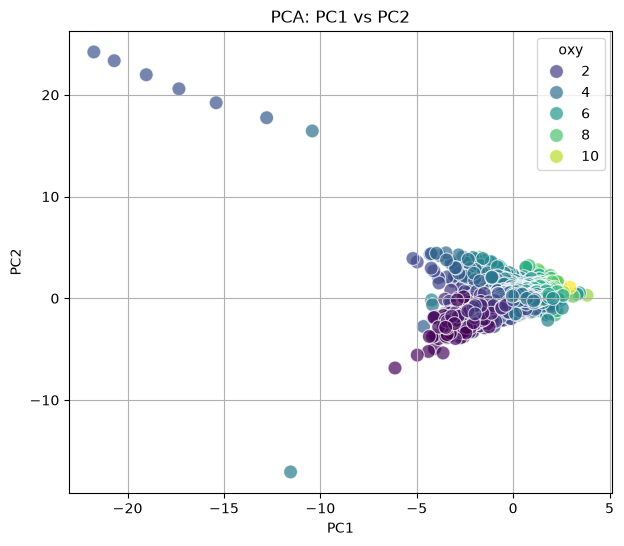

In [22]:
#plot the PCA results with two principal components that explain the most variance
#plot two plots, color them based on 2 variables (one oxygen, another of your choice)
plt.figure(figsize=(7,6))
sns.scatterplot(
    data = df_combined,
    x='PC1',
    y='PC2',
    hue='oxy',palette='viridis', #hue is for color coding and chose the right color map
    s=100,             #s is for marker size
    alpha = 0.7  #alpha is for marker transparency
)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA: PC1 vs PC2')
plt.grid(True)
plt.show()

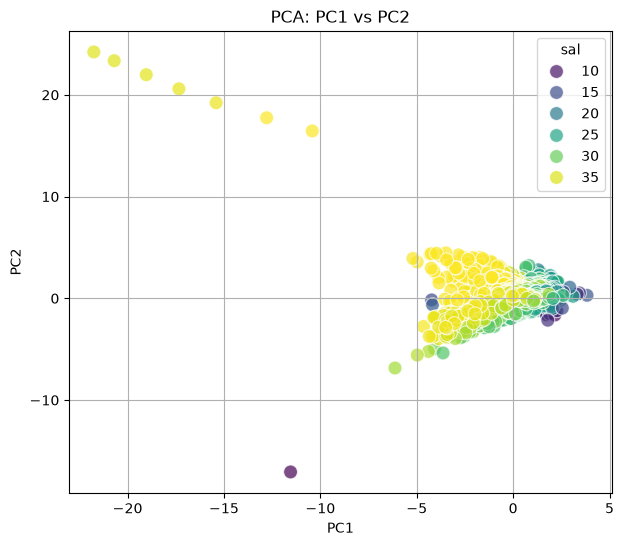

In [23]:
plt.figure(figsize=(7,6))
sns.scatterplot(
    data = df_combined,
    x='PC1',
    y='PC2',
    hue='sal',palette='viridis', #hue is for color coding and chose the right color map
    s=100,             #s is for marker size
    alpha = 0.7  #alpha is for marker transparency
)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA: PC1 vs PC2')
plt.grid(True)
plt.show()

In [26]:
#print out the co-efficients (loading) for each PC
loadings = pd.DataFrame(
    pca.components_,
    columns=features
)
#create a new column for PC names
#they are in order from 1 to 6
loadings['PC'] = ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8']
print(loadings)

        sal       oxy       nit       sil      seat       pho      sdep  \
0 -0.384902  0.459811 -0.250466 -0.422978  0.194564 -0.273371 -0.453208   
1  0.021969  0.379335  0.024971 -0.402269 -0.305700 -0.310297  0.429594   
2 -0.558634  0.269487  0.686617  0.228258 -0.223007  0.195141 -0.062449   
3 -0.322015 -0.060489 -0.019077 -0.087811  0.776540  0.276772  0.224445   
4 -0.040640  0.221477 -0.399490 -0.169869 -0.325868  0.808910 -0.000558   
5  0.510151  0.051597  0.550396 -0.546338  0.181917  0.243866 -0.184482   
6 -0.300633 -0.322587  0.047380 -0.395506 -0.082227 -0.006998  0.583318   
7  0.288646  0.642355 -0.007988  0.340134  0.264386  0.021117  0.426008   

       bdep   PC  
0 -0.284247  PC1  
1  0.564705  PC2  
2  0.006957  PC3  
3  0.393166  PC4  
4  0.017967  PC5  
5 -0.095207  PC6  
6 -0.547556  PC7  
7 -0.369431  PC8  


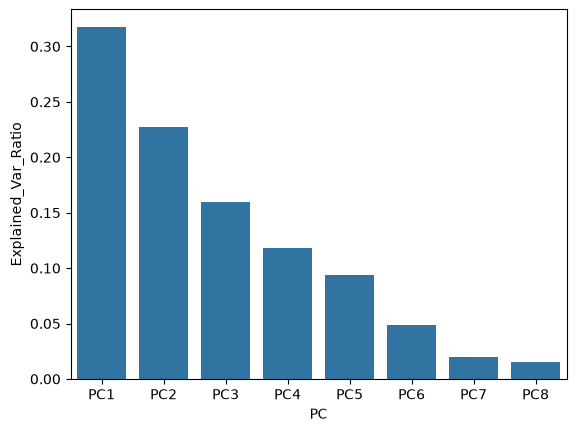

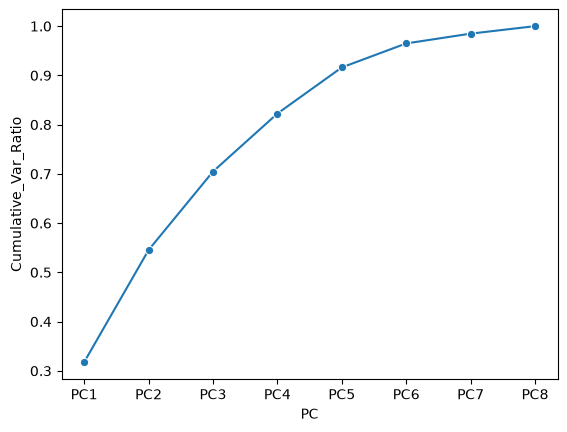

In [35]:
#plot cumulative variance explained by each PC
loadings['Explained_Var_Ratio'] = explained_var_ratio
sns.barplot(data = loadings, x='PC', y='Explained_Var_Ratio')
plt.show()

loadings['Cumulative_Explained_Var'] = loadings['Explained_Var_Ratio'].cumsum()
sns.lineplot(data = loadings, x='PC', y='Cumulative_Var_Ratio', marker='o')
plt.show()

Combining the plot/data from above
- What does PC1 and PC2 mean? (their relation to different variables, explain it with the coefficients)

- What is the trend observed for the two variables you ploted with principlate components? 

- Does it make sense considering the hypoxia process?

- What does PC3 mean?

- Based on this plot, how many and which components would you chose for your PCA plot？

- Do you think PC1 and PC2 are enough to explain the variance?

- Will include PC3 help with explaining the varianc, the oxygen level, or any other trends? Why?

In [36]:
#extract the data time and combine it with your PCA results
#convert the time format and extract month information
df_combined['date'] = lab10_observation['odate'].reset_index(drop=True)
df_combined['date'] = pd.to_datetime(df_combined['date'])
df_combined['month'] = df_combined['date'].dt.month
df_combined.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,sal,oxy,nit,sil,seat,pho,sdep,bdep,date,month
0,1.538667,0.057060,2.247329,-0.328224,0.440258,-1.080791,0.968147,-0.925517,20.1993,4.573,4.08,9.00,21.4497,0.49,4.2,10.2,2004-04-03 15:05:00.000002,4
1,0.711747,0.118639,0.666530,-1.023053,0.470911,-0.034654,0.435230,-0.442621,29.5492,4.248,2.72,6.69,21.3889,0.49,4.9,10.2,2004-04-03 15:05:00.000002,4
2,-0.650835,-0.771489,-0.152593,-0.943000,-0.160890,-0.537404,1.162147,-1.663656,30.1078,0.350,1.79,12.18,21.3224,0.34,9.5,10.2,2004-04-03 15:05:00.000002,4
3,1.565793,0.831221,0.816746,-0.769715,0.811582,-0.117826,-0.008155,-0.222924,28.1494,5.961,1.47,1.48,21.7144,0.40,2.1,19.8,2004-04-03 16:49:59.999999,4
4,0.424593,0.260773,2.226206,-0.687129,0.728515,0.760571,-0.272429,0.058877,29.0810,5.841,8.66,11.44,21.6544,1.32,2.2,19.8,2004-04-03 16:49:59.999999,4


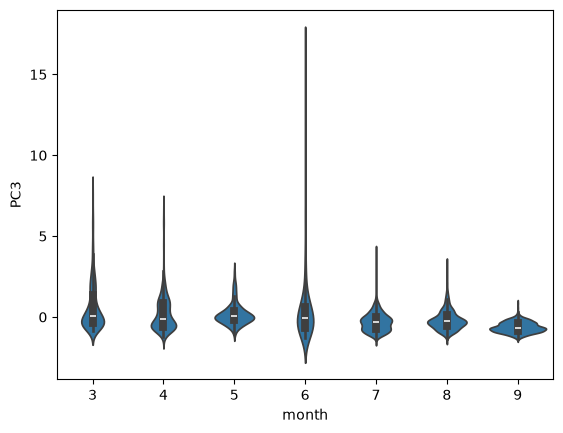

In [ ]:
#plot violin plot of PC3 (hypoxia related) vs month to see if there is seasonal variability
sns.violinplot(
    data=df_combined,
    x='month',
    y='PC3'
    )
plt.xlabel('month')
plt.ylabel('PC3')
#plt.title('PCA: PC1 vs PC2')
plt.show()

In [ ]:
#perform ANOVA analysis to see if there is significant seasonal variability in PC3
#hint: you would need to extract the data for each month and pc3, 
#then run a tukey's test to see which months are significantly different from each other
#see the code from anova labs
#load related packages if they were not

In [ ]:

#produce a tukey's test plot comparing the months


- How many months are significantly different than August? 
- What does this mean? Explain in relation to what PC3 mean and how is that related to hypoxia process.